# Modelo de la ruta de atención declarada en el Atlántico

## Clasificación con el CNPV 2018

Alejandro Carvajal y Mateo Chang

Este cuaderno documenta de principio a fin el modelo vigente del proyecto (versión 2). Complementa el [análisis exploratorio](EDA_acceso_salud_Atlantico_CNPV2018.ipynb): allí se describen los datos; aquí se construye, se entrena y se evalúa el clasificador.

Pregunta predictiva. Entre las personas del Atlántico que declararon un problema de salud en los 30 días previos al censo, sin hospitalización, ¿qué tan bien permiten sus características y su contexto ordenar quiénes quedaron fuera de la ruta formal definida por el proyecto?

Resultado. Un boosting de histogramas con 28 variables alcanzó AP = 0,375 en la prueba interna, frente a 0,211 de la prevalencia y 0,339 de la versión 1. Su discriminación es moderada (ROC-AUC = 0,696).

Qué no es este modelo. La etiqueta clasifica una acción principal declarada en 2018. No mide atención denegada, necesidad clínica ni barreras causales. El modelo es retrospectivo, se evaluó dentro del mismo censo y no debe usarse para decidir sobre personas.

### Cómo usar este cuaderno

Para leerlo no hace falta ejecutar nada: las salidas están guardadas y solo contienen agregados. Para reejecutarlo se necesitan las dependencias de `ml_salud/requirements.txt`, `ipykernel`, `plotly` y `kaleido` (que usa el Chrome del equipo para las imágenes de respaldo) y los cuatro CSV del CNPV 2018 del departamento 08 ([DANE](https://microdatos.dane.gov.co/catalog/643)), que no se distribuyen. Coloque esos archivos en `datos/` o indique su carpeta en la variable de entorno `CNPV_DATOS`. El cuaderno entrena los tres modelos candidatos con los parámetros ya seleccionados; la búsqueda completa de parámetros se repite con `python -m ml_salud.entrenar --data-dir RUTA`.

### Vocabulario

| En este cuaderno y en el Bookdown | En el código | En el análisis exploratorio |
|:--|:--|:--|
| Fuera de la ruta formal | `SIN_ACCESO = 1`, equivalente a `ACCESO_FORMAL_SALUD = 0` | «No accedió» |
| Dentro de la ruta formal | `SIN_ACCESO = 0`, equivalente a `ACCESO_FORMAL_SALUD = 1` | «Accedió» |

Las tres columnas nombran la misma regla operativa, definida en la sección 2.

## 1. Preparación del entorno

In [1]:
import json
import os
from html import escape
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import plotly
import plotly.graph_objects as go
import sklearn
from IPython.display import HTML, display
from plotly.subplots import make_subplots
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline

# El modelo se mantiene una sola vez, junto a los entregables.
import sys
PROYECTO = next(p for p in (Path.cwd(), Path.cwd().parent)
                if (p / 'ml_salud' / 'esquema.py').is_file())
sys.path.insert(0, str(PROYECTO))

from ml_salud.contexto import FEATURES_V2, NUMERIC_V2, prepare_features_v2
from ml_salud.entrenar import (
    SEED, calibration_bins, encoded_preprocessor, group_ids, hist_preprocessor,
    load_data, metricas, optimize_threshold, priorizacion, split_three,
)
from ml_salud.esquema import CATEGORICAL, DWELL_FEATURES, HOUSE_FEATURES, PERSON_FEATURES
from graficos_plotly import BASE, DENTRO, FUERA, GRUPO_A, GRUPO_B, REFERENCIA, TINTA3, mostrar_figura, rotular

DATOS = Path(os.environ.get("CNPV_DATOS", str(PROYECTO / "datos")))
RESULTADOS = (PROYECTO / "ml_salud/resultados")
SALIDAS_V2 = (PROYECTO / "ml_salud/experimento_contexto/salidas")
informe = json.loads((RESULTADOS / "resultados.json").read_text(encoding="utf-8"))
informe_v1 = json.loads((PROYECTO / "ml_salud/resultados_v1/resultados.json").read_text(encoding="utf-8"))
decision = json.loads((SALIDAS_V2 / "decision.json").read_text(encoding="utf-8"))
brecha = json.loads((SALIDAS_V2 / "brecha.json").read_text(encoding="utf-8"))

# Las gráficas son interactivas y usan la gama Petróleo de las aplicaciones (graficos_plotly.py):
# azul para quienes quedan dentro de la ruta formal, naranja para quienes quedan fuera y otra
# pareja para comparar series. Cada una lleva una imagen de respaldo para visores sin JavaScript.


def entero(x):
    return f"{int(x):,}".replace(",", ".")


def decimal(x, n=3):
    return f"{x:.{n}f}".replace(".", ",")


def porcentaje(x, n=1):
    return decimal(100 * x, n) + "\u00a0%"


def ver(tabla, titulo=None):
    # Tabla sin índice; sirve también como vista alternativa de cada gráfica.
    if titulo:
        display(HTML(f"<p style='margin:1em 0 .4em'>{escape(titulo)}</p>"))
    display(HTML(tabla.to_html(index=False, border=0, escape=False)))


ver(pd.DataFrame({"librería": ["pandas", "numpy", "scikit-learn", "plotly"],
                  "versión": [pd.__version__, np.__version__, sklearn.__version__, plotly.__version__]}))

librería,versión
pandas,3.0.5
numpy,2.5.2
scikit-learn,1.9.1
plotly,7.1.0


## 2. Datos, cohorte y variable respuesta

Se usan cuatro archivos del CNPV 2018 para el Atlántico: personas, hogares, viviendas y el marco geográfico `MGN`, que asigna cada vivienda a su sección censal. `load_data` aplica la regla de la etiqueta, une los archivos con validación de cardinalidad y se detiene si alguna persona queda sin enlace. Antes de continuar se comprueba que las huellas SHA-256 coincidan con las del modelo guardado.

In [2]:
df, fuente = load_data(DATOS, with_context=True)
assert fuente["source_sha256"] == informe["source"]["source_sha256"], "Los CSV no son los del modelo guardado"

ver(pd.DataFrame([{"Archivo": nombre, "SHA-256 (inicio)": huella[:16] + "…"}
                  for nombre, huella in fuente["source_sha256"].items()]), "Archivos fuente verificados")
ver(pd.DataFrame({
    "Etapa": ["Personas en el archivo censal", "Declararon un problema de salud sin hospitalización",
              "Sin etiqueta clasificable (excluidas)", "Cohorte analítica"],
    "Personas": [entero(fuente[k]) for k in ("people", "sick", "unlabeled", "labeled")],
}), "Flujo de la cohorte")

Archivo,SHA-256 (inicio)
CNPV2018_5PER_A2_08.CSV,e55981e90717fa23…
CNPV2018_2HOG_A2_08.CSV,e4ab3a377decabcc…
CNPV2018_1VIV_A2_08.CSV,428ee27091e9c6ef…
CNPV2018_MGN_A2_08.CSV,fffaef93c140ad37…


Etapa,Personas
Personas en el archivo censal,2.342.265
Declararon un problema de salud sin hospitalización,136.114
Sin etiqueta clasificable (excluidas),80
Cohorte analítica,136.034


La unidad es la persona. La cohorte no es toda la población del Atlántico: solo incluye a quienes declararon el problema de salud y tienen una respuesta clasificable.

### Regla de la etiqueta

`P_QUEHIZO_PPAL` registra el tratamiento principal y `PA_LO_ATENDIERON` indica si la entidad atendió a la persona.

- Dentro de la ruta formal: acudió a su EPS o entidad y fue atendida, o acudió a un médico particular.
- Fuera de la ruta formal: acudió a su EPS o entidad y no fue atendida, o declaró otra acción principal o ninguna.

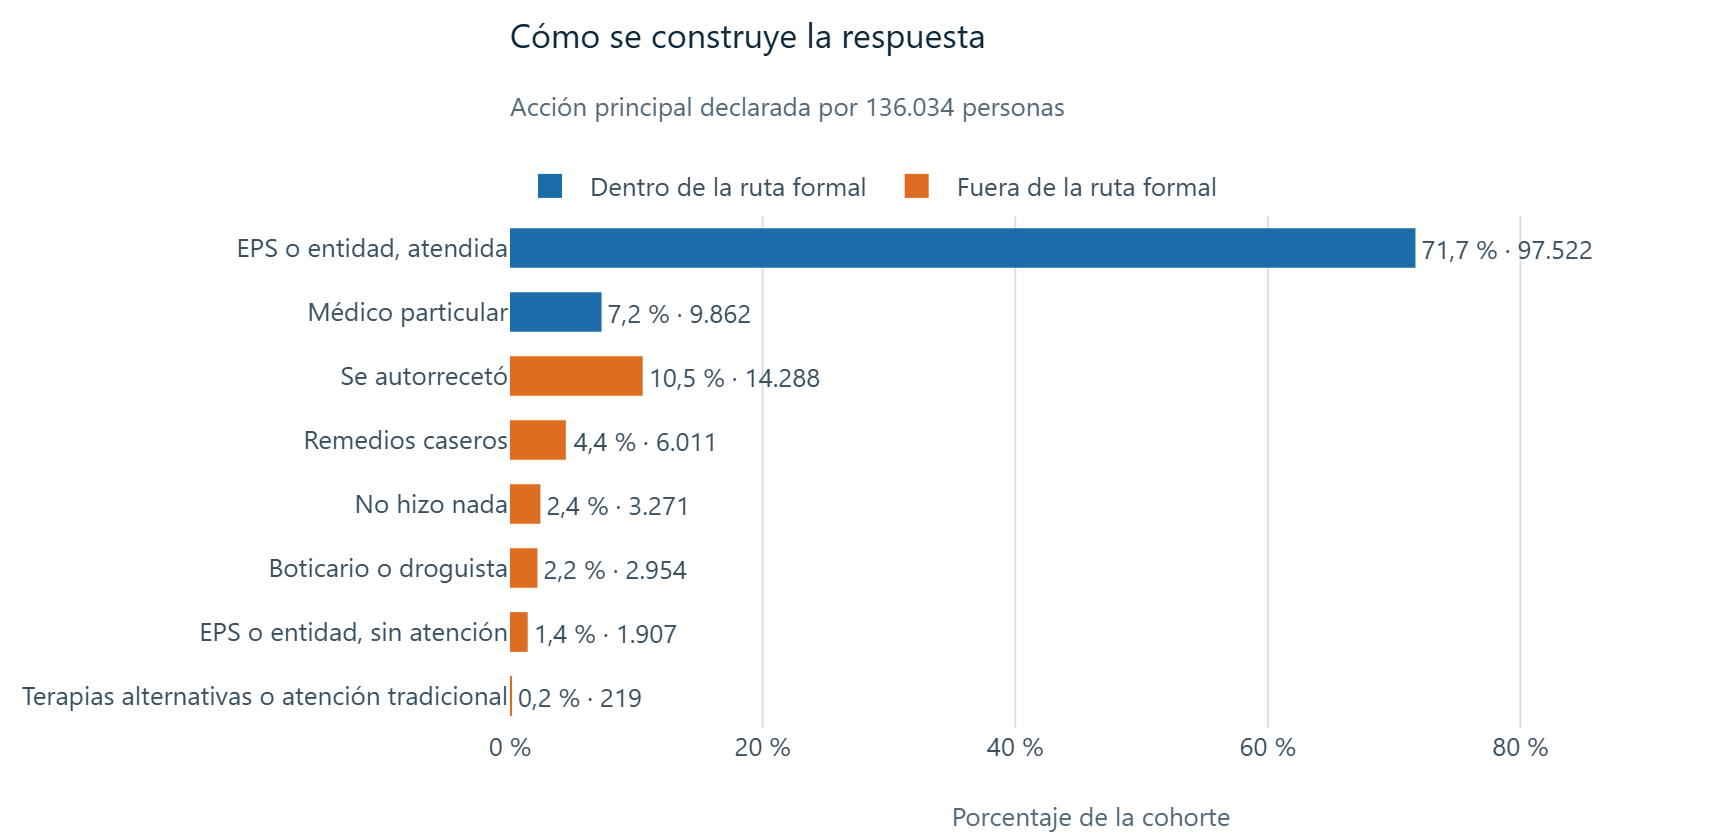

Ruta,Personas,Porcentaje
Dentro,107.384,"78,94 %"
Fuera,28.650,"21,06 %"


In [3]:
accion = df["P_QUEHIZO_PPAL"]
etiquetas = fuente["label_breakdown"]
filas = [
    ("EPS o entidad, atendida", "Dentro", etiquetas["eps_atendido"]),
    ("Médico particular", "Dentro", etiquetas["medico_particular"]),
    ("Se autorrecetó", "Fuera", int(accion.eq(8).sum())),
    ("Remedios caseros", "Fuera", int(accion.eq(7).sum())),
    ("No hizo nada", "Fuera", int(accion.eq(9).sum())),
    ("Boticario o droguista", "Fuera", int(accion.eq(3).sum())),
    ("EPS o entidad, sin atención", "Fuera", etiquetas["eps_no_atendido"]),
    # Las categorías 5 y 6 son muy pequeñas: se publican agrupadas con la 4.
    ("Terapias alternativas o atención tradicional", "Fuera", int(accion.isin([4, 5, 6]).sum())),
]
rutas = pd.DataFrame(filas, columns=["accion", "ruta", "n"])
assert rutas["n"].sum() == len(df)
rutas["pct"] = rutas["n"] / len(df)

orden = rutas.iloc[::-1]
fig = go.Figure()
for ruta, color, nombre in (("Dentro", DENTRO, "Dentro de la ruta formal"), ("Fuera", FUERA, "Fuera de la ruta formal")):
    parte = orden[orden["ruta"] == ruta]
    fig.add_trace(go.Bar(
        x=parte["pct"] * 100, y=parte["accion"], orientation="h", name=nombre, marker_color=color, width=0.62,
        text=[f"{porcentaje(p)} · {entero(n)}" for p, n in zip(parte["pct"], parte["n"])],
        textposition="outside", cliponaxis=False, customdata=parte["n"],
        hovertemplate="%{y}<br>%{x:.1f} % de la cohorte<br>%{customdata:,} personas<extra></extra>",
    ))
fig.update_yaxes(categoryorder="array", categoryarray=orden["accion"].tolist(), showgrid=False)
fig.update_xaxes(range=[0, 92], title_text="Porcentaje de la cohorte", ticksuffix=" %")
rotular(fig, "Cómo se construye la respuesta", f"Acción principal declarada por {entero(len(df))} personas")
mostrar_figura(fig, alto=420)

fuera = df["SIN_ACCESO"].sum()
ver(rutas.groupby("ruta", sort=False)["n"].sum().rename("Personas").reset_index().assign(
    Porcentaje=lambda t: [porcentaje(v / len(df), 2) for v in t["Personas"]],
    Personas=lambda t: [entero(v) for v in t["Personas"]],
).rename(columns={"ruta": "Ruta"}), "Resumen de la clase")

De las 28.650 personas fuera de la ruta formal, solo 1.907 acudieron a su EPS y no recibieron atención. Las demás declararon otra acción principal o ninguna. Por eso el 21,06 % no es una tasa de atención denegada ni describe la situación actual del departamento. La clase es minoritaria, de modo que la exactitud sería engañosa: predecir siempre «dentro» acertaría cerca de ocho veces de cada diez sin encontrar ningún caso.

## 3. Variables de entrada

El modelo usa 28 variables. Veintiséis describen a la persona, su hogar y su vivienda. Las otras dos describen su contexto de salud.

In [4]:
ver(pd.DataFrame([
    {"Nivel": "Persona", "Variables": len(PERSON_FEATURES), "Códigos": ", ".join(PERSON_FEATURES)},
    {"Nivel": "Hogar", "Variables": len(HOUSE_FEATURES), "Códigos": ", ".join(HOUSE_FEATURES)},
    {"Nivel": "Vivienda", "Variables": len(DWELL_FEATURES), "Códigos": ", ".join(DWELL_FEATURES)},
    {"Nivel": "Contexto de salud", "Variables": 2, "Códigos": "HOGAR_OTROS_ENFERMOS, SECCION_PCT_ENFERMOS"},
]))
assert len(FEATURES_V2) == 28

Nivel,Variables,Códigos
Persona,10,"U_MPIO, UA_CLASE, P_SEXO, P_EDADR, P_PARENTESCOR, PA1_GRP_ETNIC, CONDICION_FISICA, P_ALFABETA, P_NIVEL_ANOSR, P_EST_CIVIL"
Hogar,5,"H_NRO_CUARTOS, H_NRO_DORMIT, H_DONDE_PREPALIM, H_AGUA_COCIN, HA_TOT_PER"
Vivienda,11,"V_TIPO_VIV, V_MAT_PARED, V_MAT_PISO, VA_EE, VA1_ESTRATO, VB_ACU, VC_ALC, VD_GAS, VE_RECBAS, VF_INTERNET, V_TIPO_SERSA"
Contexto de salud,2,"HOGAR_OTROS_ENFERMOS, SECCION_PCT_ENFERMOS"


### Qué se excluyó para evitar fugas

| Variable | Motivo |
|:--|:--|
| `P_QUEHIZO_PPAL`, `PA_LO_ATENDIERON` | Construyen la respuesta |
| `PA1_CALIDAD_SERV` | Solo se conoce después de usar el servicio |
| `P_TRABAJO`, `PA_ASISTENCIA` | Se miden en el mismo censo y podrían ser consecuencia del episodio de la propia persona |
| `P_ENFERMO` de la persona | Define la cohorte: vale 1 para todos |
| Identificadores | No describen a la persona |

### Las dos variables de contexto

- `HOGAR_OTROS_ENFERMOS`: otras personas del mismo hogar que declararon un problema de salud.
- `SECCION_PCT_ENFERMOS`: proporción que lo declaró entre las personas de la misma sección censal fuera del hogar, con respuesta válida.

Se calculan en [`ml_salud/contexto.py`](https://github.com/acarvajalb21/EDAPYTHON/blob/main/ml_salud/contexto.py) con `P_ENFERMO` de todas las personas del archivo censal. No usan la acción declarada ni la etiqueta, así que no revelan la respuesta. Sin embargo, se miden en el mismo censo: no son información previa al episodio.

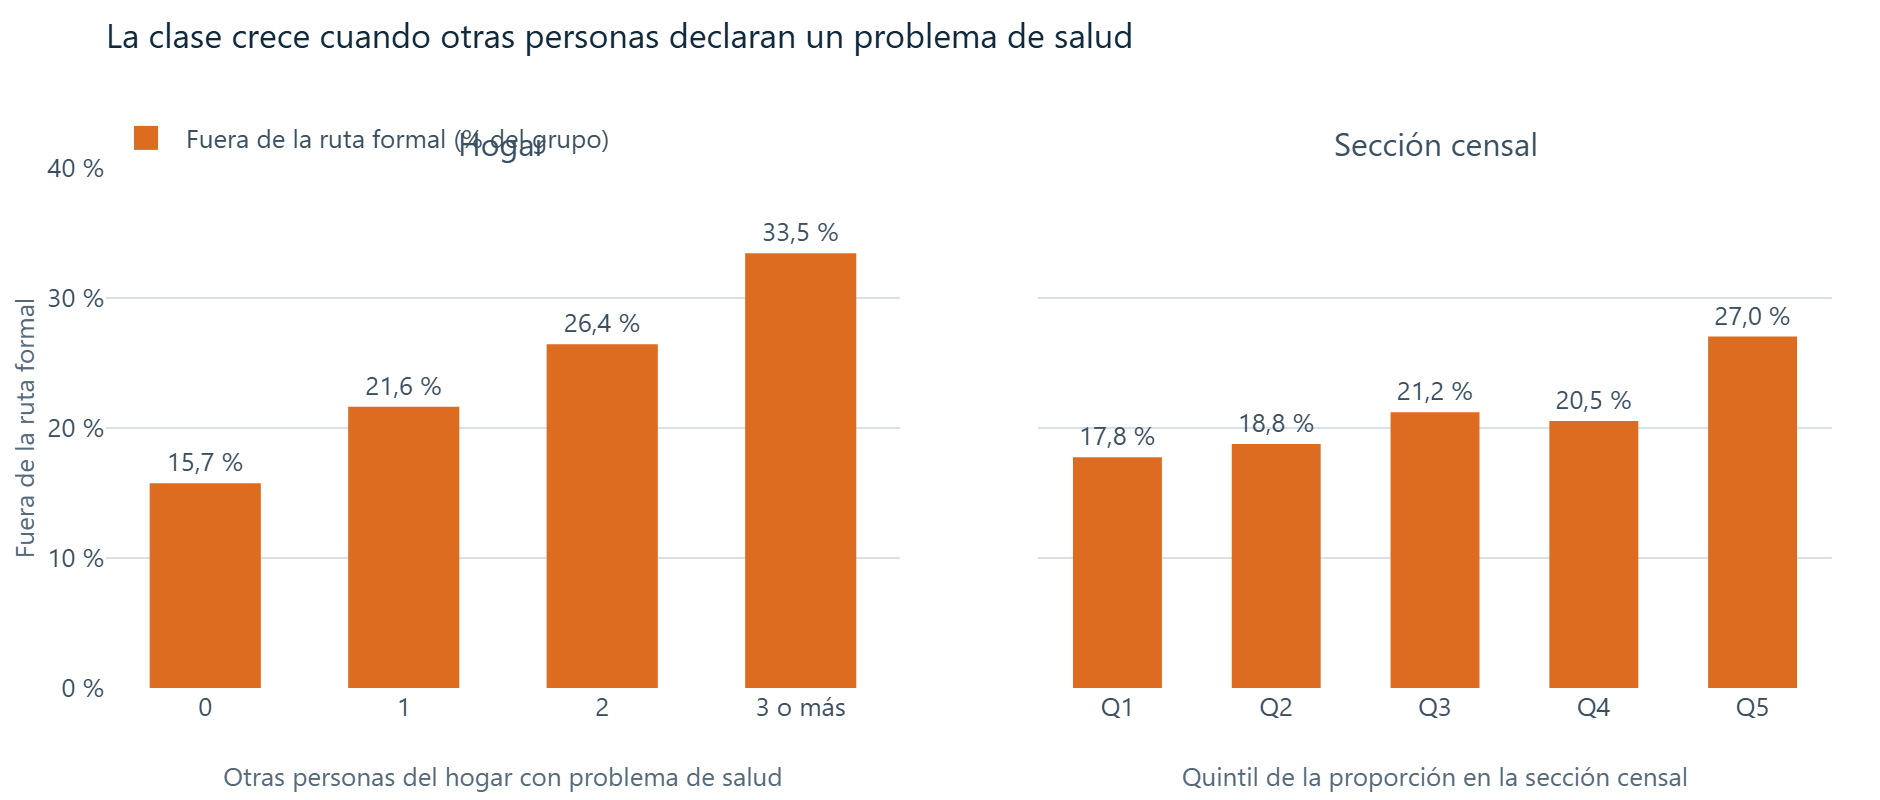

Otros enfermos (3 = 3 o más),Personas,Se autorrecetó,Remedios caseros,Boticario,No hizo nada,EPS o entidad
0,61.255,"7,2 %","3,2 %","1,5 %","2,2 %","78,0 %"
1,38.937,"10,8 %","4,6 %","2,2 %","2,5 %","72,3 %"
2,20.132,"14,0 %","5,7 %","2,8 %","2,7 %","67,7 %"
3,15.710,"18,0 %","7,3 %","3,8 %","2,6 %","62,8 %"


Quintil,Personas,Proporción media en la sección,Fuera de la ruta formal
1,27.207,"2,9 %","17,8 %"
2,27.207,"5,6 %","18,8 %"
3,27.209,"7,9 %","21,2 %"
4,27.213,"11,1 %","20,5 %"
5,27.198,"16,6 %","27,0 %"


In [5]:
otros = df["HOGAR_OTROS_ENFERMOS"].clip(upper=3).astype(int)
hogar = df.groupby(otros)["SIN_ACCESO"].agg(personas="size", tasa="mean")
quintil = pd.qcut(df["SECCION_PCT_ENFERMOS"], 5, labels=False) + 1
seccion = df.groupby(quintil).agg(personas=("SIN_ACCESO", "size"), tasa=("SIN_ACCESO", "mean"),
                                  media=("SECCION_PCT_ENFERMOS", "mean"))

fig = make_subplots(rows=1, cols=2, shared_yaxes=True, subplot_titles=("Hogar", "Sección censal"), horizontal_spacing=0.08)
for columna, (tabla, etiquetas_x, xlabel) in enumerate((
    (hogar, ["0", "1", "2", "3 o más"], "Otras personas del hogar con problema de salud"),
    (seccion, [f"Q{q}" for q in seccion.index], "Quintil de la proporción en la sección censal"),
), start=1):
    fig.add_trace(go.Bar(
        x=etiquetas_x, y=tabla["tasa"] * 100, marker_color=FUERA, width=0.56,
        name="Fuera de la ruta formal (% del grupo)", legendgroup="fuera", showlegend=columna == 1,
        text=[porcentaje(v) for v in tabla["tasa"]], textposition="outside", cliponaxis=False,
        customdata=tabla["personas"],
        hovertemplate="%{x}<br>Fuera de la ruta formal: %{y:.1f} %<br>%{customdata:,} personas<extra></extra>",
    ), row=1, col=columna)
    fig.update_xaxes(title_text=xlabel, showgrid=False, row=1, col=columna)
fig.update_xaxes(type="category")
fig.update_yaxes(range=[0, 40], ticksuffix=" %")
fig.update_yaxes(title_text="Fuera de la ruta formal", row=1, col=1)
fig.update_layout(showlegend=True)
rotular(fig, "La clase crece cuando otras personas declaran un problema de salud")
mostrar_figura(fig, alto=400, ancho=940)

cambio = pd.DataFrame({"personas": hogar["personas"].map(entero)})
for codigo, nombre in ((8, "Se autorrecetó"), (7, "Remedios caseros"), (3, "Boticario"), (9, "No hizo nada"), (1, "EPS o entidad")):
    cambio[nombre] = accion.eq(codigo).groupby(otros).mean().map(porcentaje)
ver(cambio.reset_index().rename(columns={"HOGAR_OTROS_ENFERMOS": "Otros enfermos (3 = 3 o más)", "personas": "Personas"}),
    "Acción principal según las otras personas del hogar con problema de salud")
ver(pd.DataFrame({"Quintil": seccion.index, "Personas": seccion["personas"].map(entero).to_numpy(),
                  "Proporción media en la sección": seccion["media"].map(porcentaje).to_numpy(),
                  "Fuera de la ruta formal": seccion["tasa"].map(porcentaje).to_numpy()}),
    "Clase según la proporción con problema de salud en la sección censal")

Cómo leerlo. La clase crece con el número de otras personas que declararon un problema de salud, y lo que más sube es la autorreceta. «No hizo nada» casi no cambia. Es una asociación, no un efecto causal.

La proporción por sección varía mucho: su media va de 2,9 % en el quintil más bajo a 16,6 % en el más alto. Hipótesis no comprobada: estas variables pueden captar también problemas más leves, que se resuelven sin consulta, o diferencias en quién respondió y cómo se recogió el dato. El censo no permite separar esas explicaciones. Por eso no deben leerse como barreras ni como causas.

## 4. Particiones y preprocesamiento

La cohorte se divide en entrenamiento, validación y prueba con estratificación por clase y agrupación por vivienda: las personas de una misma vivienda quedan en una sola partición. Así, el modelo no se evalúa con casi las mismas condiciones del hogar que vio al ajustarse. `split_three` reparte la cohorte en siete grupos iguales con `StratifiedGroupKFold` (semilla 42): cinco forman el entrenamiento (≈ 71,4 %), uno la validación (≈ 14,3 %) y uno la prueba (≈ 14,3 %). Se detiene si alguna vivienda aparece en dos particiones.

- Entrenamiento: ajustar los modelos y buscar parámetros con validación cruzada de tres pliegues, también agrupada por vivienda.
- Validación: elegir el modelo y el umbral.
- Prueba: describir el resultado final. No se usa para elegir nada.

In [6]:
x = prepare_features_v2(df)
y = df["SIN_ACCESO"].to_numpy()
viviendas = group_ids(df)
train, val, test = split_three(x, y, viviendas)

ver(pd.DataFrame([
    {"Partición": nombre, "Personas": entero(len(i)), "Porcentaje de la cohorte": porcentaje(len(i) / len(y)),
     "Viviendas": entero(len(set(viviendas[i]))),
     "Fuera de la ruta formal": entero(y[i].sum()), "Prevalencia": porcentaje(y[i].mean(), 2)}
    for nombre, i in (("Entrenamiento", train), ("Validación", val), ("Prueba", test))
]))
ver(pd.DataFrame({"Tipo": ["Categóricas", "Numéricas"], "Variables": [len(CATEGORICAL), len(NUMERIC_V2)],
                  "Tratamiento": ["Códigos de «no informa» y vacíos como categoría de ausencia",
                                  "Mediana aprendida en entrenamiento, con marcador de faltante"]}),
    "Preprocesamiento dentro de cada pipeline")

Partición,Personas,Porcentaje de la cohorte,Viviendas,Fuera de la ruta formal,Prevalencia
Entrenamiento,97.167,"71,4 %",63.927,20.465,"21,06 %"
Validación,19.433,"14,3 %",12.718,4.092,"21,06 %"
Prueba,19.434,"14,3 %",12.695,4.093,"21,06 %"


Tipo,Variables,Tratamiento
Categóricas,22,Códigos de «no informa» y vacíos como categoría de ausencia
Numéricas,6,"Mediana aprendida en entrenamiento, con marcador de faltante"


`prepare_features_v2` valida los códigos censales y convierte los valores de «no informa» de forma determinista. La imputación y la codificación se aprenden dentro del pipeline, solo con los datos de ajuste. No se usa sobremuestreo sintético.

## 5. Modelos candidatos

Se comparan tres enfoques frente a una referencia que asigna a todas las personas la prevalencia. La métrica principal es precisión promedio (Average Precision, AP) de la clase fuera de la ruta formal: resume cómo se concentran los casos al ordenar por puntuación y su valor de referencia es la prevalencia. Con clases desbalanceadas, la curva de precisión y sensibilidad describe el rendimiento mejor que la curva ROC ([Saito y Rehmsmeier, 2015](https://doi.org/10.1371/journal.pone.0118432)). El campo `pr_auc` de los resultados guarda este valor.

Aquí se entrena cada candidato con los parámetros que ganaron la búsqueda en validación cruzada. Cada resultado se compara con el guardado por `ml_salud.entrenar`.

In [7]:
def construir(nombre):
    p = {clave.removeprefix("model__"): valor for clave, valor in informe["models"][nombre]["best_params"].items()}
    if nombre == "logistica":
        return Pipeline([("prep", encoded_preprocessor(age_as_category=True, numeric=NUMERIC_V2)),
                         ("model", LogisticRegression(max_iter=1000, solver="lbfgs", **p))])
    if nombre == "random_forest":
        return Pipeline([("prep", encoded_preprocessor(numeric=NUMERIC_V2)),
                         ("model", RandomForestClassifier(n_estimators=120, n_jobs=4, random_state=SEED, **p))])
    return Pipeline([("prep", hist_preprocessor(numeric=NUMERIC_V2)),
                     ("model", HistGradientBoostingClassifier(categorical_features=list(range(len(CATEGORICAL))),
                                                              early_stopping=False, random_state=SEED, **p))])


NOMBRES = {"logistica": "Regresión logística", "random_forest": "Bosque aleatorio",
           "hist_gradient_boosting": "Boosting de histogramas"}
modelos, val_scores = {}, {}
for nombre in NOMBRES:
    modelos[nombre] = construir(nombre).fit(x.iloc[train], y[train])
    val_scores[nombre] = modelos[nombre].predict_proba(x.iloc[val])[:, 1]
    guardado = informe["models"][nombre]["validation"]["pr_auc"]
    assert abs(average_precision_score(y[val], val_scores[nombre]) - guardado) < 1e-8, nombre

ver(pd.DataFrame([{"Modelo": "Prevalencia", "AP validación cruzada": "—",
                   "AP validación": decimal(informe["models"]["baseline"]["validation"]["pr_auc"]),
                   "ROC-AUC validación": decimal(0.5),
                   "Brier validación": decimal(informe["models"]["baseline"]["validation"]["brier"])}]
                 + [{"Modelo": etiqueta, "AP validación cruzada": decimal(informe["models"][nombre]["cv_pr_auc"]),
                     "AP validación": decimal(average_precision_score(y[val], val_scores[nombre])),
                     "ROC-AUC validación": decimal(roc_auc_score(y[val], val_scores[nombre])),
                     "Brier validación": decimal(brier_score_loss(y[val], val_scores[nombre]))}
                    for nombre, etiqueta in NOMBRES.items()]),
    "Comparación en validación")

Modelo,AP validación cruzada,AP validación,ROC-AUC validación,Brier validación
Prevalencia,—,"0,211","0,500","0,166"
Regresión logística,"0,359","0,369","0,686","0,154"
Bosque aleatorio,"0,363","0,370","0,688","0,154"
Boosting de histogramas,"0,374","0,386","0,701","0,151"


In [8]:
busqueda = pd.DataFrame(informe["models"]["hist_gradient_boosting"]["cv_candidates"])
parametros = pd.json_normalize(busqueda["params"]).rename(columns=lambda c: c.removeprefix("model__"))
busqueda = pd.concat([parametros, busqueda[["mean_pr_auc", "std_pr_auc"]]], axis=1).sort_values("mean_pr_auc", ascending=False)
ver(pd.DataFrame({"Tasa": busqueda["learning_rate"].map(lambda v: decimal(v, 2)), "Hojas": busqueda["max_leaf_nodes"],
                  "Iteraciones": busqueda["max_iter"], "AP media (CV)": busqueda["mean_pr_auc"].map(lambda v: decimal(v, 4)),
                  "Desviación": busqueda["std_pr_auc"].map(lambda v: decimal(v, 4))}).head(5),
    "Cinco mejores combinaciones del boosting en la búsqueda guardada")

Tasa,Hojas,Iteraciones,AP media (CV),Desviación
"0,04",15,500,"0,3742","0,0033"
"0,04",31,500,"0,3741","0,0028"
"0,04",31,320,"0,3733","0,0024"
"0,10",31,180,"0,3732","0,0029"
"0,10",15,320,"0,3732","0,0045"


Gana el boosting de histogramas, con 15 hojas, tasa 0,04 y 500 iteraciones. Trata municipio, sexo y las demás variables nominales como categorías, no como cantidades, y no usa parada temprana para no crear otra partición de datos.

### ¿Por qué escogimos el boosting de histogramas?

La regla de elección se fijó antes de mirar la prueba: gana el candidato con mayor precisión promedio (AP) en **validación**. La celda siguiente la aplica y añade las demás métricas para comprobar que la elección no depende de una sola cifra. Las razones:

1. **Gana con la regla fijada de antemano**: tiene la mayor AP en validación cruzada y en validación.
2. **Gana también en ROC-AUC y Brier**: ordena mejor y sus probabilidades se equivocan menos.
3. **La ventaja es pequeña, pero distinta de cero**: el intervalo pareado del 95 % de la diferencia de AP frente al segundo modelo (bootstrap que remuestrea viviendas completas) no incluye cero. Ese intervalo se calcula con los modelos ya entrenados: no cubre la variabilidad del entrenamiento ni de la selección.
4. **Se ajusta a estos datos**: trata municipio, sexo y materiales como categorías y aprende combinaciones entre variables sin escribirlas a mano. La regresión logística, más sencilla, queda cerca; la mejora del boosting es real pero modesta.

In [9]:
eleccion = pd.DataFrame([{"codigo": n, "Modelo": NOMBRES[n],
                          "AP validación cruzada": informe["models"][n]["cv_pr_auc"],
                          "AP validación": average_precision_score(y[val], val_scores[n]),
                          "ROC-AUC validación": roc_auc_score(y[val], val_scores[n]),
                          "Brier validación": brier_score_loss(y[val], val_scores[n])} for n in NOMBRES])
eleccion = eleccion.sort_values("AP validación", ascending=False).reset_index(drop=True)
eleccion.insert(0, "Puesto", range(1, len(eleccion) + 1))
ganador = eleccion["codigo"].iloc[0]
assert ganador == informe["selected_model"], "La regla de validación no reproduce la elección guardada"

delta = informe["test_uncertainty"]["intervals_95"]["delta_ap_vs_competitor"]
rival = informe["test_uncertainty"]["competitor"]
metricas_cols = [c for c in eleccion.columns if c.startswith(("AP", "ROC", "Brier"))]
ver(eleccion.drop(columns="codigo").assign(**{c: eleccion[c].map(decimal) for c in metricas_cols}),
    "Regla de elección: mayor AP en validación (la prueba no interviene)")
ver(pd.DataFrame([{"Comparación": f"{NOMBRES[ganador]} menos {NOMBRES[rival]}",
                   "Diferencia de AP en prueba": decimal(informe["test_metrics"][ganador]["pr_auc"] - informe["test_metrics"][rival]["pr_auc"]),
                   "IC 95 % inferior": decimal(delta[0]), "IC 95 % superior": decimal(delta[1]),
                   "Método": "Bootstrap pareado, 250 remuestreos de viviendas"}]),
    "Tamaño de la ventaja frente al segundo modelo en prueba")

Puesto,Modelo,AP validación cruzada,AP validación,ROC-AUC validación,Brier validación
1,Boosting de histogramas,"0,374","0,386","0,701","0,151"
2,Bosque aleatorio,"0,363","0,370","0,688","0,154"
3,Regresión logística,"0,359","0,369","0,686","0,154"


Comparación,Diferencia de AP en prueba,IC 95 % inferior,IC 95 % superior,Método
Boosting de histogramas menos Bosque aleatorio,"0,012","0,005","0,020","Bootstrap pareado, 250 remuestreos de viviendas"


## 6. Por qué existe una versión 2

Antes de este modelo, una revisión probó nueve variantes de la versión 1: tratamiento de faltantes, densidad del hogar, regularización, tasas y una mezcla con regresión logística. Ninguna mejoró de forma relevante ([auditoría](https://github.com/acarvajalb21/EDAPYTHON/blob/main/ml_salud/experimentos_2026_10/INFORME_AUDITORIA.md)). El ajuste de parámetros estaba agotado, así que se buscó información que el modelo no tenía.

Una exploración dentro del entrenamiento mostró que casi toda la ganancia venía de las dos variables de contexto. Antes de consultar la validación se fijó un [protocolo](https://github.com/acarvajalb21/EDAPYTHON/blob/main/ml_salud/experimento_contexto/PROTOCOLO.md) con una regla de adopción. La comparación usó los parámetros publicados de la versión 1 para aislar el efecto de las variables.

In [10]:
v26, v28 = decision["validacion"]["modelo_26"], decision["validacion"]["modelo_28"]
viv, sec = decision["cv_viviendas_no_vistas"], decision["cv_secciones_no_vistas"]
par = decision["comparacion_pareada"]
dif = decision["sensibilidad_validacion"]["con_dificultad"]
criterios = decision["criterios"]
ver(pd.DataFrame([
    {"Condición": "Ganancia de AP en validación ≥ 0,010", "Resultado": decimal(par["delta_ap"], 4), "Cumple": criterios["ganancia_ap_validacion"]},
    {"Condición": "Intervalo pareado del 95 % sobre cero", "Resultado": f"{decimal(par['delta_ap_interval_95'][0], 4)} a {decimal(par['delta_ap_interval_95'][1], 4)}", "Cumple": criterios["intervalo_sobre_cero"]},
    {"Condición": "Brier de validación sin empeorar más de 0,002", "Resultado": f"{decimal(v26['brier'], 4)} a {decimal(v28['brier'], 4)}", "Cumple": criterios["brier_no_empeora"]},
    {"Condición": "Ganancia ≥ 0,010 en secciones no vistas", "Resultado": decimal(sec["delta_ap"], 4), "Cumple": criterios["ganancia_secciones_no_vistas"]},
    {"Condición": "Sensibilidad con dificultad funcional sin caer más de 0,03", "Resultado": f"{decimal(dif['modelo_26']['sensibilidad'], 3)} a {decimal(dif['modelo_28']['sensibilidad'], 3)}", "Cumple": criterios["sensibilidad_dificultad"]},
]).assign(Cumple=lambda t: t["Cumple"].map({True: "Sí", False: "No"})), "Regla de adopción")
ver(pd.DataFrame([
    {"Medida": "AP en validación", "26 variables": decimal(v26["pr_auc"]), "28 variables": decimal(v28["pr_auc"])},
    {"Medida": "AP en CV, viviendas no vistas", "26 variables": decimal(viv["ap_26"]), "28 variables": decimal(viv["ap_28"])},
    {"Medida": "AP en CV, secciones no vistas", "26 variables": decimal(sec["ap_26"]), "28 variables": decimal(sec["ap_28"])},
]), "Comparación con los mismos parámetros")

Condición,Resultado,Cumple
"Ganancia de AP en validación ≥ 0,010","0,0373",Sí
Intervalo pareado del 95 % sobre cero,"0,0260 a 0,0492",Sí
"Brier de validación sin empeorar más de 0,002","0,1557 a 0,1515",Sí
"Ganancia ≥ 0,010 en secciones no vistas","0,0298",Sí
"Sensibilidad con dificultad funcional sin caer más de 0,03","0,436 a 0,432",Sí


Medida,26 variables,28 variables
AP en validación,"0,346","0,383"
"AP en CV, viviendas no vistas","0,336","0,373"
"AP en CV, secciones no vistas","0,327","0,357"


La columna de secciones no vistas es la prueba más exigente: evalúa zonas que no participaron en el ajuste, de modo que una variable no gana solo por reconocer secciones ya vistas. La mejora se mantiene. Esta comparación no consultó la partición de prueba.

## 7. Modelo final y umbral

Se comprueba que el modelo entrenado aquí es el mismo que quedó guardado. Después se recupera el umbral: el valor que maximiza F1 en validación.

In [11]:
final = modelos["hist_gradient_boosting"]
artefacto = joblib.load(RESULTADOS / "modelo_sin_acceso.joblib")
assert artefacto["features"] == FEATURES_V2 and artefacto["model_version"] == 2
diferencia = np.abs(val_scores["hist_gradient_boosting"]
                    - artefacto["pipeline"].predict_proba(df.iloc[val][FEATURES_V2])[:, 1]).max()
assert diferencia < 1e-12

umbrales = {nombre: optimize_threshold(y[val], val_scores[nombre])[0] for nombre in NOMBRES}
umbral = umbrales["hist_gradient_boosting"]
assert abs(umbral - artefacto["threshold_no_access"]) < 1e-12
ver(pd.DataFrame({"Comprobación": ["Mayor diferencia frente al modelo guardado, en validación", "Umbral elegido en validación"],
                  "Valor": [f"{diferencia:.1e}".replace(".", ","), decimal(umbral, 4)]}))

Comprobación,Valor
"Mayor diferencia frente al modelo guardado, en validación","0,0e+00"
Umbral elegido en validación,"0,2235"


## 8. Evaluación en la prueba interna

Modelo y umbral ya están fijados. La prueba describe el resultado; no se toma ninguna decisión con ella. Esta partición ya se había observado con la versión 1, de modo que es una evaluación interna, no una confirmación externa.

In [12]:
test_scores = {nombre: modelos[nombre].predict_proba(x.iloc[test])[:, 1] for nombre in NOMBRES}
yt = y[test]
s = test_scores["hist_gradient_boosting"]
metricas_prueba = {nombre: metricas(yt, test_scores[nombre], umbrales[nombre]) for nombre in NOMBRES}
for nombre, valores in metricas_prueba.items():
    assert abs(valores["pr_auc"] - informe["test_metrics"][nombre]["pr_auc"]) < 1e-8, nombre

base = informe["test_metrics"]["baseline"]
ver(pd.DataFrame(
    [{"Modelo": "Prevalencia", "AP": decimal(base["pr_auc"]), "ROC-AUC": decimal(base["roc_auc"]), "Brier": decimal(base["brier"]),
      "F1": "—", "Precisión": "—", "Sensibilidad": "—"}]
    + [{"Modelo": NOMBRES[n], "AP": decimal(m["pr_auc"]), "ROC-AUC": decimal(m["roc_auc"]), "Brier": decimal(m["brier"]),
        "F1": decimal(m["f1"]), "Precisión": porcentaje(m["precision"]), "Sensibilidad": porcentaje(m["recall"])}
       for n, m in metricas_prueba.items()]), "Resultados en prueba, cada modelo con su umbral de validación")

intervalos = informe["test_uncertainty"]["intervals_95"]
ver(pd.DataFrame([{"Medida": etiqueta, "Inferior": decimal(intervalos[clave][0]), "Superior": decimal(intervalos[clave][1])}
                  for etiqueta, clave in (("AP", "selected_ap"), ("ROC-AUC", "selected_roc_auc"), ("Brier", "selected_brier"))]),
    "Intervalos internos del 95 % del modelo final (bootstrap de 250 remuestreos por vivienda)")

m = metricas_prueba["hist_gradient_boosting"]["confusion"]
ver(pd.DataFrame({"": ["Dato: dentro de la ruta", "Dato: fuera de la ruta"],
                  "Predicción: dentro": [entero(m["tn"]), entero(m["fn"])],
                  "Predicción: fuera": [entero(m["fp"]), entero(m["tp"])]}), "Matriz de confusión del modelo final")

Modelo,AP,ROC-AUC,Brier,F1,Precisión,Sensibilidad
Prevalencia,"0,211","0,500","0,166",—,—,—
Regresión logística,"0,369","0,677","0,154","0,410","30,2 %","64,1 %"
Bosque aleatorio,"0,363","0,680","0,155","0,413","29,6 %","68,2 %"
Boosting de histogramas,"0,375","0,696","0,152","0,428","33,1 %","60,6 %"


Medida,Inferior,Superior
AP,"0,352","0,396"
ROC-AUC,"0,685","0,707"
Brier,"0,149","0,156"


,Predicción: dentro,Predicción: fuera
Dato: dentro de la ruta,10.324,5.017
Dato: fuera de la ruta,1.613,2.480


### ¿Por qué las métricas se ven bajas? ¿El modelo predice?

Sí predice, pero hay que leerlo con la métrica adecuada. La tabla siguiente compara tres escenarios en la prueba:

- **Siempre «dentro de la ruta»**: no usa modelo y tiene la exactitud más alta, porque cuatro de cada cinco personas están dentro. Nunca encuentra un caso. Por eso la exactitud no sirve para elegir.
- **Modelo con el corte convencional de 0,5**: como la clase es minoritaria y las probabilidades están calibradas, rara vez pasan de 0,5; el modelo casi no marca a nadie.
- **Modelo con el umbral elegido en validación (F1)**: detecta la mayoría de los casos a cambio de falsas alarmas.

La última tabla muestra que el modelo sí ordena: entre las puntuaciones más altas, la proporción de casos es más del doble de la prevalencia (*lift*). El límite está en los datos: el censo no registra la gravedad del problema, el tiempo de espera, la distancia ni las preferencias, que deciden buena parte de la acción declarada.

In [13]:
def escenario(nombre, pred):
    tn = int(((pred == 0) & (yt == 0)).sum())
    fp = int(((pred == 1) & (yt == 0)).sum())
    fn = int(((pred == 0) & (yt == 1)).sum())
    tp = int(((pred == 1) & (yt == 1)).sum())
    sens, espec = tp / (tp + fn), tn / (tn + fp)
    return {"Escenario": nombre, "Exactitud": porcentaje((tn + tp) / len(yt)), "Exactitud balanceada": porcentaje((sens + espec) / 2),
            "Sensibilidad": porcentaje(sens), "Precisión": porcentaje(tp / (tp + fp)) if tp + fp else "—", "Marcadas": entero(tp + fp)}


umbral_final = informe["threshold_from_validation"]
ver(pd.DataFrame([escenario("Siempre «dentro» (sin modelo)", np.zeros_like(yt)),
                  escenario("Modelo con umbral 0,5", (s >= 0.5).astype(int)),
                  escenario(f"Modelo con umbral validado ({decimal(umbral_final, 4)})", (s >= umbral_final).astype(int))]),
    "Por qué la exactitud engaña: tres escenarios en la prueba")
ver(pd.DataFrame([{"Se revisa": porcentaje(r["fraction"], 0), "Personas": entero(r["reviewed"]), "Fuera de la ruta": entero(r["positives_found"]),
                   "Precisión": porcentaje(r["precision"]), "Lift sobre la prevalencia": decimal(r["lift"], 2)}
                  for r in priorizacion(yt, s)]),
    f"El modelo sí ordena: precisión entre las puntuaciones más altas (prevalencia {porcentaje(yt.mean())})")

Escenario,Exactitud,Exactitud balanceada,Sensibilidad,Precisión,Marcadas
Siempre «dentro» (sin modelo),"78,9 %","50,0 %","0,0 %",—,0
"Modelo con umbral 0,5","79,1 %","52,0 %","5,2 %","55,0 %",389
"Modelo con umbral validado (0,2235)","65,9 %","63,9 %","60,6 %","33,1 %",7.497


Se revisa,Personas,Fuera de la ruta,Precisión,Lift sobre la prevalencia
5 %,972,493,"50,7 %","2,41"
10 %,1.944,906,"46,6 %","2,21"
20 %,3.887,1.561,"40,2 %","1,91"


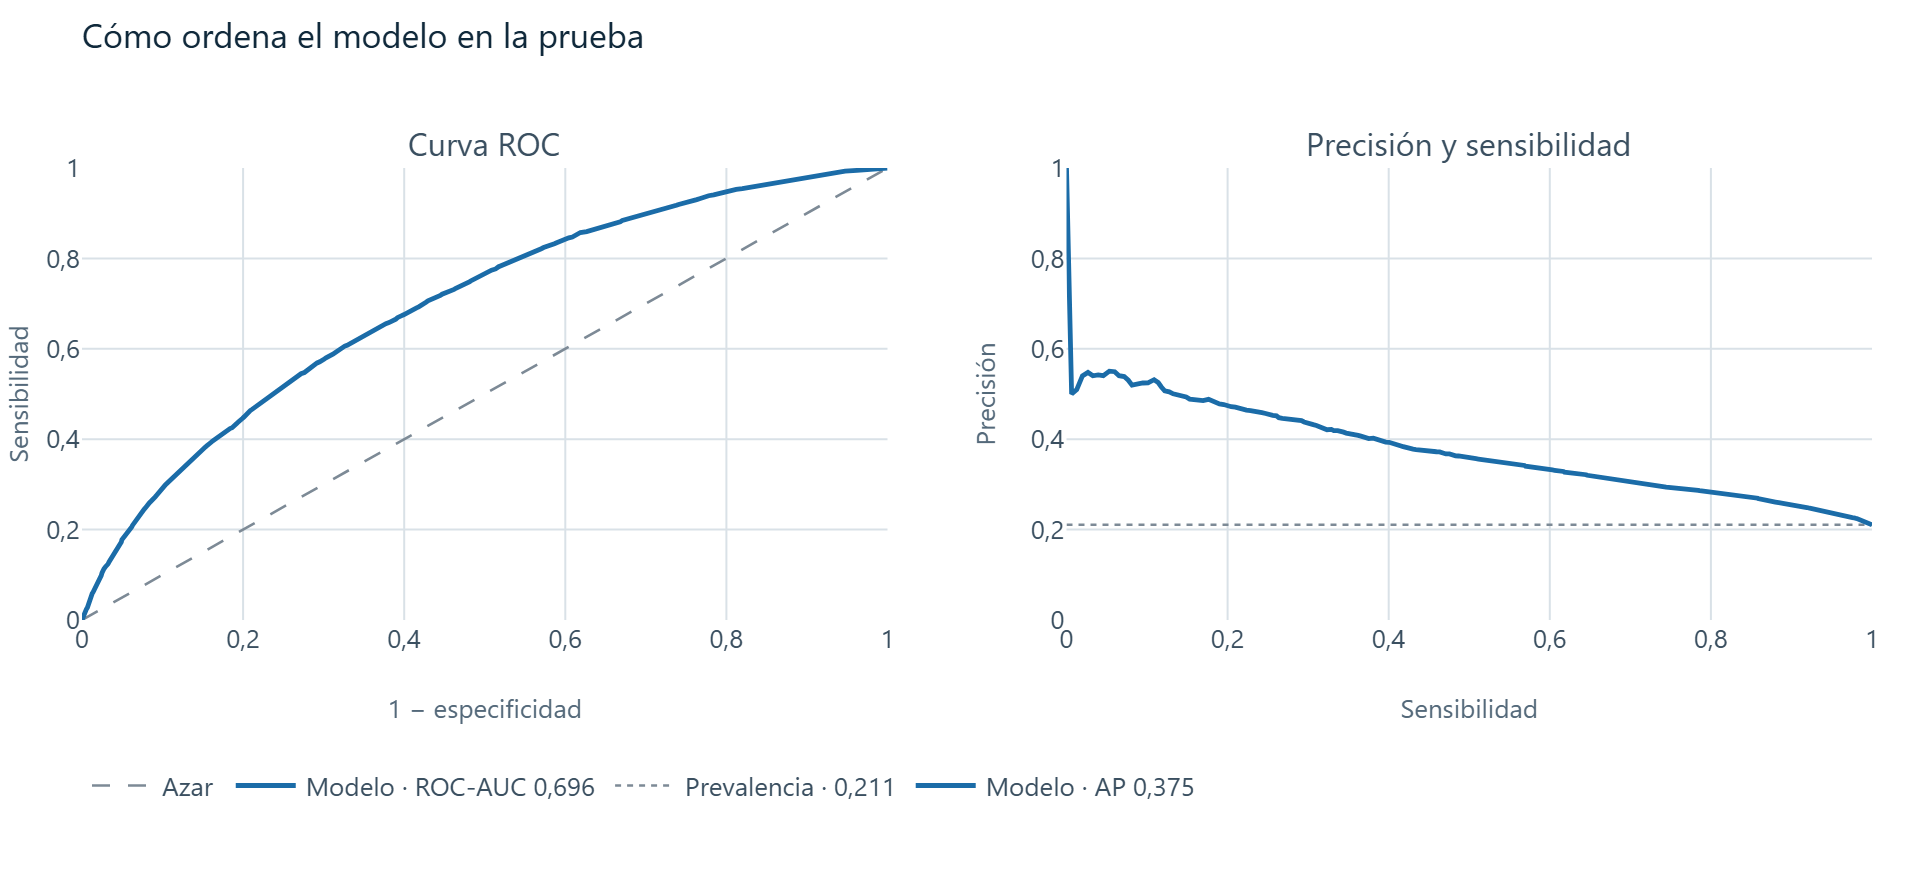

In [14]:
fpr, tpr, _ = roc_curve(yt, s)
precision, recall, _ = precision_recall_curve(yt, s)
prevalencia = yt.mean()

# Se grafican 400 puntos de cada curva: bastan para su forma y cada uno agrega a muchas personas.
def muestra(total, puntos=400):
    return np.unique(np.linspace(0, total - 1, min(puntos, total)).round().astype(int))

i_roc, i_pr = muestra(len(fpr)), muestra(len(recall))
fig = make_subplots(rows=1, cols=2, subplot_titles=("Curva ROC", "Precisión y sensibilidad"), horizontal_spacing=0.1)
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", name="Azar",
                         line=dict(color=REFERENCIA, dash="dash", width=1.3), hoverinfo="skip"), row=1, col=1)
fig.add_trace(go.Scatter(x=fpr[i_roc], y=tpr[i_roc], mode="lines", name=f"Modelo · ROC-AUC {decimal(roc_auc_score(yt, s))}",
                         line=dict(color=DENTRO, width=2.4),
                         hovertemplate="1 − especificidad: %{x:.3f}<br>Sensibilidad: %{y:.3f}<extra></extra>"), row=1, col=1)
fig.add_trace(go.Scatter(x=[0, 1], y=[prevalencia, prevalencia], mode="lines", name=f"Prevalencia · {decimal(prevalencia)}",
                         line=dict(color=REFERENCIA, dash="dot", width=1.3), hoverinfo="skip"), row=1, col=2)
fig.add_trace(go.Scatter(x=recall[i_pr], y=precision[i_pr], mode="lines", name=f"Modelo · AP {decimal(average_precision_score(yt, s))}",
                         line=dict(color=DENTRO, width=2.4),
                         hovertemplate="Sensibilidad: %{x:.3f}<br>Precisión: %{y:.3f}<extra></extra>"), row=1, col=2)
fig.update_xaxes(range=[0, 1], title_text="1 − especificidad", row=1, col=1)
fig.update_yaxes(range=[0, 1], title_text="Sensibilidad", row=1, col=1)
fig.update_xaxes(range=[0, 1], title_text="Sensibilidad", row=1, col=2)
fig.update_yaxes(range=[0, 1], title_text="Precisión", row=1, col=2)
fig.update_layout(legend=dict(y=-0.3, yanchor="top"), margin=dict(b=130))
rotular(fig, "Cómo ordena el modelo en la prueba")
mostrar_figura(fig, alto=440, ancho=960)

Cómo leerlo. El modelo ordena mejor que el azar y que la prevalencia, pero la discriminación es moderada: ROC-AUC de 0,696. La precisión más alta aparece solo entre las puntuaciones superiores y cae pronto.

### Calibración

Una probabilidad está bien calibrada si, entre quienes reciben cerca de 30 %, cerca del 30 % pertenece a la clase.

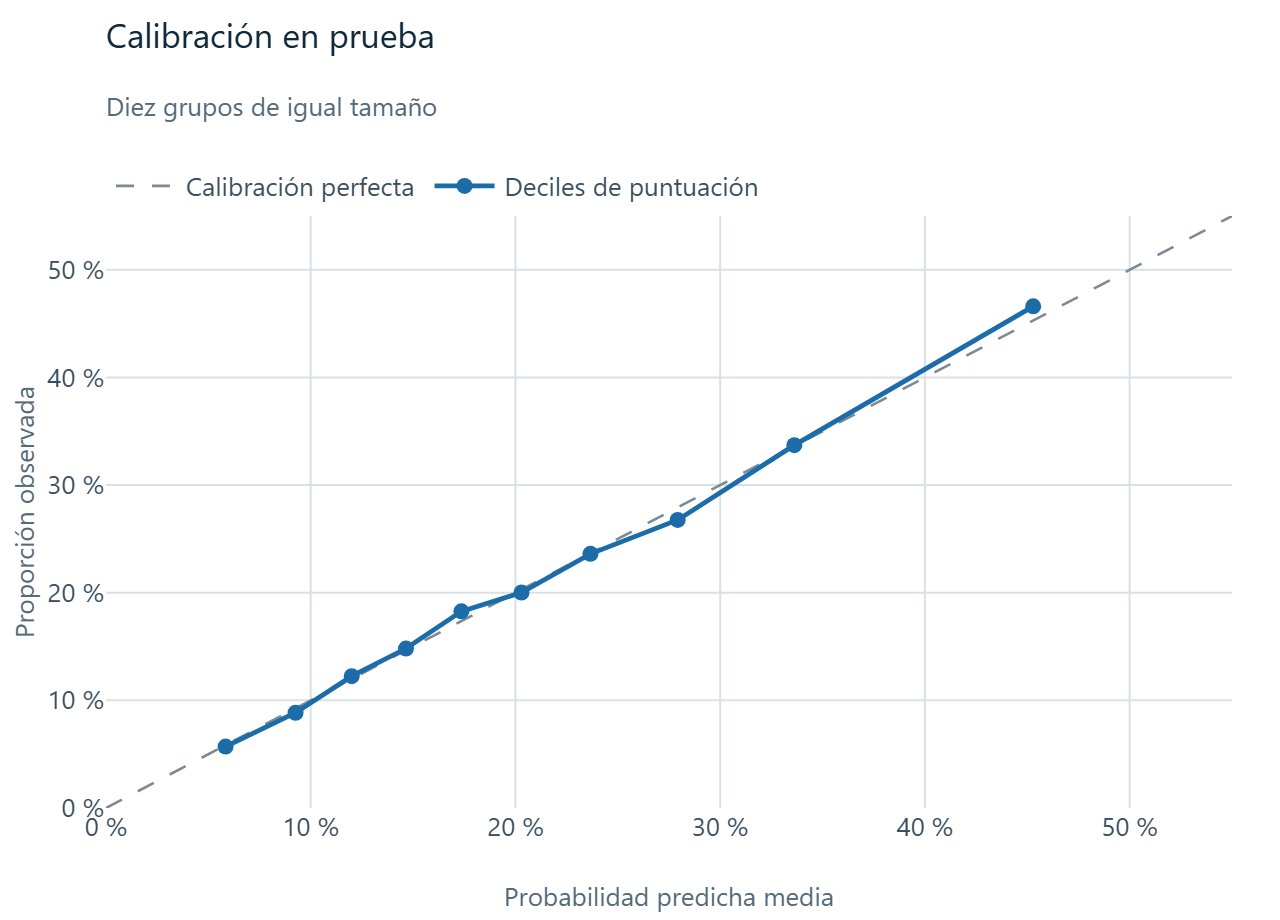

Decil,Personas,Predicho,Observado
1,1.944,"5,8 %","5,7 %"
2,1.943,"9,3 %","8,9 %"
3,1.943,"12,0 %","12,2 %"
4,1.944,"14,7 %","14,8 %"
5,1.943,"17,4 %","18,3 %"
6,1.943,"20,3 %","20,0 %"
7,1.944,"23,7 %","23,6 %"
8,1.943,"27,9 %","26,8 %"
9,1.943,"33,6 %","33,7 %"
10,1.944,"45,3 %","46,6 %"


In [15]:
deciles = pd.DataFrame(calibration_bins(yt, s))
fig = go.Figure()
fig.add_trace(go.Scatter(x=[0, 55], y=[0, 55], mode="lines", name="Calibración perfecta",
                         line=dict(color=REFERENCIA, dash="dash", width=1.3), hoverinfo="skip"))
fig.add_trace(go.Scatter(x=deciles["mean_predicted"] * 100, y=deciles["observed"] * 100, mode="lines+markers", name="Deciles de puntuación",
                         line=dict(color=DENTRO, width=2.4), marker=dict(size=8), customdata=deciles["n"],
                         hovertemplate="Predicha: %{x:.1f} %<br>Observada: %{y:.1f} %<br>%{customdata:,} personas<extra></extra>"))
fig.update_xaxes(range=[0, 55], ticksuffix=" %", title_text="Probabilidad predicha media")
fig.update_yaxes(range=[0, 55], ticksuffix=" %", title_text="Proporción observada")
rotular(fig, "Calibración en prueba", "Diez grupos de igual tamaño")
mostrar_figura(fig, alto=460, ancho=640)
ver(pd.DataFrame({"Decil": range(1, len(deciles) + 1), "Personas": deciles["n"].map(entero),
                  "Predicho": deciles["mean_predicted"].map(porcentaje), "Observado": deciles["observed"].map(porcentaje)}),
    "Valores de la gráfica")

Los puntos siguen de cerca la diagonal. Es una buena señal interna, pero no valida el modelo para otro año o territorio.

### Umbral y priorización

El umbral de F1 no es una recomendación de uso: el proyecto no tiene costos ni capacidad definidos. Mover el umbral intercambia alcance por falsas alarmas.

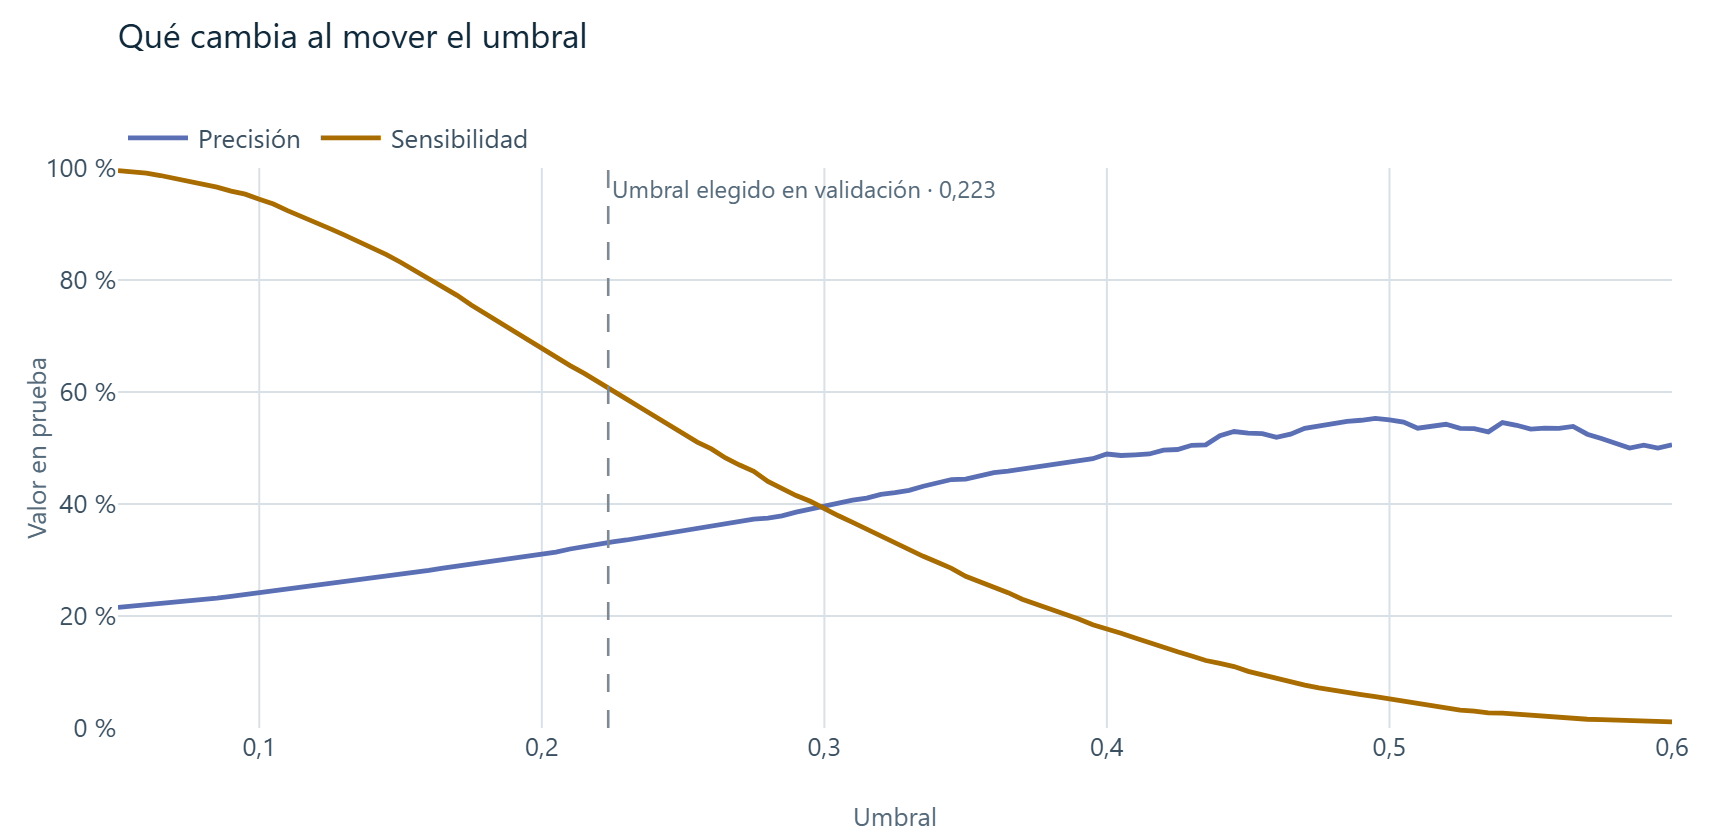

Se revisa,Personas,De la clase,Precisión,Sensibilidad,Veces la prevalencia
5 % con mayor puntuación,972,493,"50,7 %","12,0 %","2,41"
10 % con mayor puntuación,1.944,906,"46,6 %","22,1 %","2,21"
20 % con mayor puntuación,3.887,1.561,"40,2 %","38,1 %","1,91"


In [16]:
rejilla = np.linspace(0.05, 0.6, 111)
curva = pd.DataFrame([{"umbral": t, "precision": yt[s >= t].mean(), "sensibilidad": (s[yt == 1] >= t).mean()} for t in rejilla])

fig = go.Figure()
fig.add_trace(go.Scatter(x=curva["umbral"], y=curva["precision"] * 100, mode="lines", name="Precisión",
                         line=dict(color=GRUPO_A, width=2.4), hovertemplate="Umbral %{x:.3f}<br>Precisión: %{y:.1f} %<extra></extra>"))
fig.add_trace(go.Scatter(x=curva["umbral"], y=curva["sensibilidad"] * 100, mode="lines", name="Sensibilidad",
                         line=dict(color=GRUPO_B, width=2.4), hovertemplate="Umbral %{x:.3f}<br>Sensibilidad: %{y:.1f} %<extra></extra>"))
fig.add_vline(x=umbral, line=dict(color=REFERENCIA, dash="dash", width=1.3),
              annotation_text=f"Umbral elegido en validación · {decimal(umbral, 3)}", annotation_position="top right",
              annotation_font=dict(size=12, color=TINTA3))
fig.update_xaxes(range=[0.05, 0.6], title_text="Umbral")
fig.update_yaxes(range=[0, 100], ticksuffix=" %", title_text="Valor en prueba")
rotular(fig, "Qué cambia al mover el umbral")
mostrar_figura(fig, alto=420)

marcadas = (s >= umbral).sum()
ver(pd.DataFrame([
    {"Se revisa": porcentaje(f["fraction"], 0) + " con mayor puntuación", "Personas": entero(f["reviewed"]), "De la clase": entero(f["positives_found"]),
     "Precisión": porcentaje(f["precision"]), "Sensibilidad": porcentaje(f["recall"]), "Veces la prevalencia": decimal(f["lift"], 2)}
    for f in priorizacion(yt, s)
]), f"Priorización exploratoria. Con el umbral elegido se marcan {entero(marcadas)} de {entero(len(yt))} personas ({porcentaje(marcadas / len(yt))})")

## 9. Variables más influyentes

La importancia por permutación mide cuánto cae la AP de validación al desordenar una variable. Indica cuánto depende el modelo de cada variable, no su efecto causal ([scikit-learn](https://scikit-learn.org/stable/modules/permutation_importance.html)). Se toma de los resultados guardados.

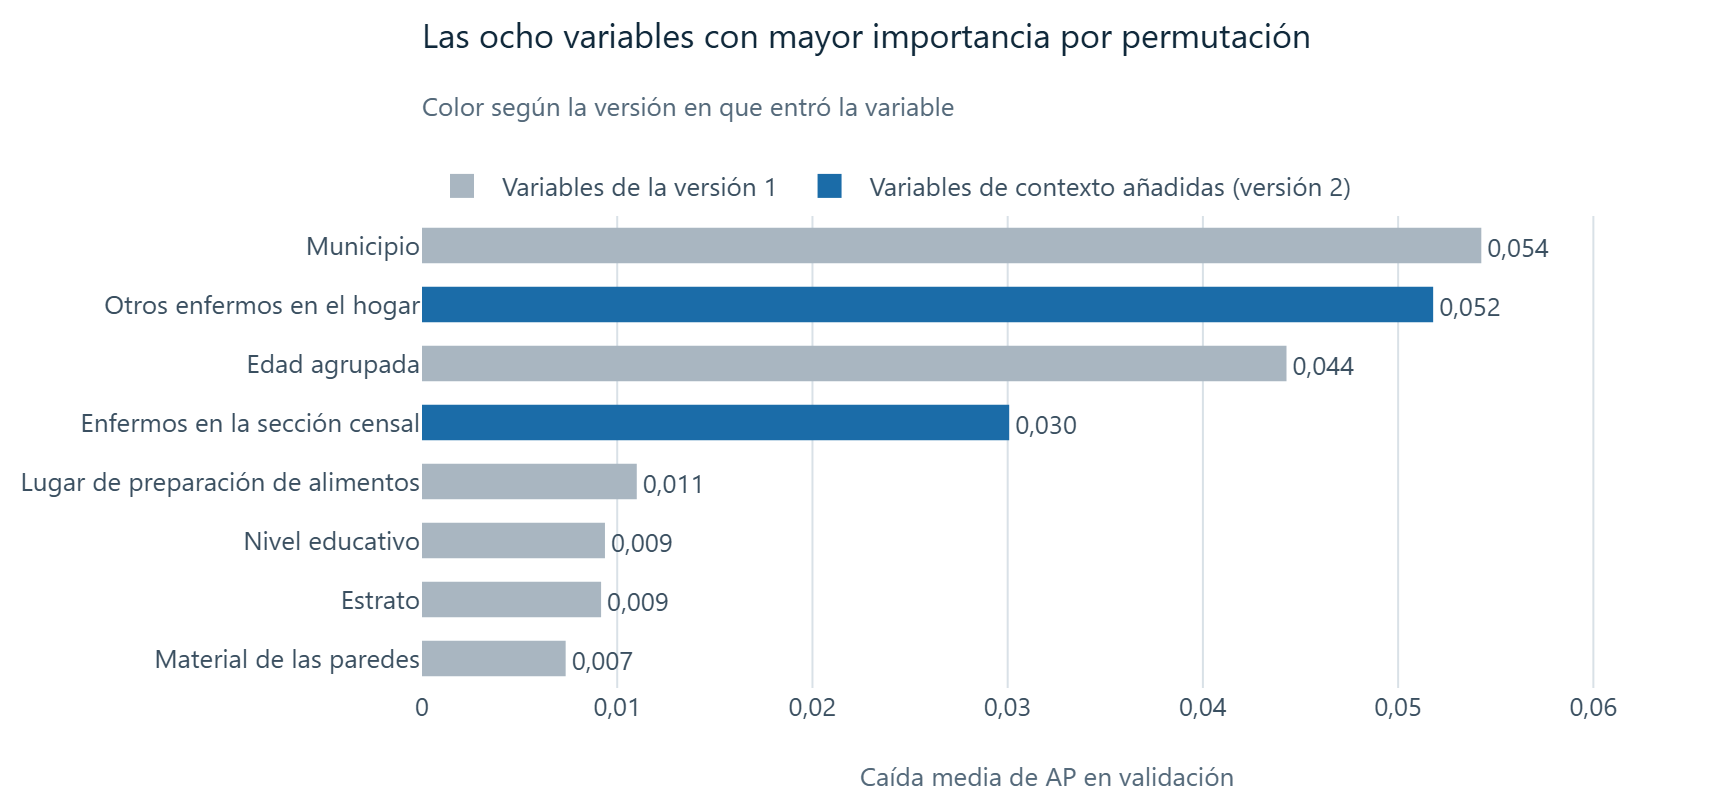

In [17]:
NOMBRES_VAR = {
    "U_MPIO": "Municipio", "HOGAR_OTROS_ENFERMOS": "Otros enfermos en el hogar", "P_EDADR": "Edad agrupada",
    "SECCION_PCT_ENFERMOS": "Enfermos en la sección censal", "H_DONDE_PREPALIM": "Lugar de preparación de alimentos",
    "P_NIVEL_ANOSR": "Nivel educativo", "VA1_ESTRATO": "Estrato", "V_MAT_PARED": "Material de las paredes",
    "HA_TOT_PER": "Personas en el hogar", "UA_CLASE": "Clase de asentamiento", "CONDICION_FISICA": "Dificultad funcional",
    "VF_INTERNET": "Internet en la vivienda", "P_SEXO": "Sexo registrado",
}
importancia = pd.DataFrame(informe["permutation_importance_validation"]).head(8).iloc[::-1]
nuevas = importancia["feature"].isin(["HOGAR_OTROS_ENFERMOS", "SECCION_PCT_ENFERMOS"])
orden = [NOMBRES_VAR.get(v, v) for v in importancia["feature"]]
fig = go.Figure()
for es_nueva, nombre, color in ((False, "Variables de la versión 1", BASE), (True, "Variables de contexto añadidas (versión 2)", DENTRO)):
    parte = importancia[nuevas == es_nueva]
    fig.add_trace(go.Bar(
        x=parte["mean_ap_drop"], y=[NOMBRES_VAR.get(v, v) for v in parte["feature"]], orientation="h", width=0.6,
        name=nombre, marker_color=color, text=[decimal(v) for v in parte["mean_ap_drop"]],
        textposition="outside", cliponaxis=False, customdata=parte["std_ap_drop"],
        hovertemplate="%{y}<br>Caída media de AP: %{x:.4f}<br>Desviación: %{customdata:.4f}<extra></extra>",
    ))
fig.update_layout(showlegend=True)
fig.update_yaxes(categoryorder="array", categoryarray=orden)
fig.update_xaxes(range=[0, importancia["mean_ap_drop"].max() * 1.18], title_text="Caída media de AP en validación")
fig.update_yaxes(showgrid=False)
rotular(fig, "Las ocho variables con mayor importancia por permutación", "Color según la versión en que entró la variable")
mostrar_figura(fig, alto=400)

Municipio y edad ya dominaban la versión 1. Ahora los acompañan las dos variables de contexto. La fuerza del municipio indica que parte del rendimiento se apoya en patrones territoriales de 2018.

## 10. Diferencias entre grupos

Un buen resultado global puede esconder errores desiguales. La tabla compara la sensibilidad por grupos en la prueba interna. La segunda fila marca a tantas personas como la versión 1 para separar el efecto del modelo del efecto del umbral.

In [18]:
ETIQUETAS = {"v1_umbral_validado": "Versión 1, su umbral", "v2_mismas_personas_marcadas": "Versión 2, mismas personas marcadas",
             "v2_umbral_validado": "Versión 2, su umbral"}
ver(pd.DataFrame([{"Escenario": ETIQUETAS[clave], "Marcadas": entero(f["flagged"]), "Precisión": porcentaje(f["precision"]),
                   "Sensibilidad": porcentaje(f["recall"]), "Con dificultad funcional": porcentaje(f["recall_difficulty"]),
                   "Sin dificultad funcional": porcentaje(f["recall_no_difficulty"]), "60 años o más": porcentaje(f["recall_60_plus"])}
                  for clave, f in brecha["same_flagged_comparison"].items()]), "Sensibilidad por grupo en la prueba interna")
ver(pd.DataFrame({"Medida": ["Sensibilidad cruda", "Sensibilidad ajustada por edad"],
                  "Con dificultad funcional": [porcentaje(brecha["raw_recall"]["1"]), porcentaje(brecha["age_standardized_recall"]["1"])],
                  "Sin dificultad funcional": [porcentaje(brecha["raw_recall"]["2"]), porcentaje(brecha["age_standardized_recall"]["2"])]}),
    "Modelo final con su umbral")

Escenario,Marcadas,Precisión,Sensibilidad,Con dificultad funcional,Sin dificultad funcional,60 años o más
"Versión 1, su umbral",9.293,"29,7 %","67,4 %","43,0 %","71,1 %","10,3 %"
"Versión 2, mismas personas marcadas",9.293,"30,6 %","69,5 %","49,8 %","72,5 %","19,3 %"
"Versión 2, su umbral",7.497,"33,1 %","60,6 %","37,9 %","64,1 %","11,6 %"


Medida,Con dificultad funcional,Sin dificultad funcional
Sensibilidad cruda,"37,9 %","64,1 %"
Sensibilidad ajustada por edad,"44,5 %","62,6 %"


Cómo leerlo. Con su propio umbral, la versión 2 marca a menos personas y por eso pierde sensibilidad. Al marcar a las mismas personas, mejora en todos los grupos. Aun así, la brecha por dificultad funcional persiste, también al ajustar por edad, y la sensibilidad entre personas de 60 años o más sigue siendo baja. Esto no identifica una causa ni demuestra discriminación, pero exige atención antes de cualquier uso.

## 11. Cómo se usa el modelo guardado

`modelo_sin_acceso.joblib` recibe las 28 columnas y devuelve una puntuación. El ejemplo usa un perfil inventado, no una persona real, para mostrar cómo responde el modelo a las dos variables de contexto. Los códigos son los del diccionario del CNPV 2018.

In [19]:
perfil = {
    "U_MPIO": 1, "UA_CLASE": 1, "P_SEXO": 2, "P_EDADR": 8, "P_PARENTESCOR": 1, "PA1_GRP_ETNIC": 6, "CONDICION_FISICA": 2,
    "P_ALFABETA": 1, "P_NIVEL_ANOSR": 3, "P_EST_CIVIL": 5, "H_NRO_CUARTOS": 3, "H_NRO_DORMIT": 2, "H_DONDE_PREPALIM": 1,
    "H_AGUA_COCIN": 1, "HA_TOT_PER": 4, "V_TIPO_VIV": 1, "V_MAT_PARED": 1, "V_MAT_PISO": 2, "VA_EE": 1, "VA1_ESTRATO": 2,
    "VB_ACU": 1, "VC_ALC": 1, "VD_GAS": 1, "VE_RECBAS": 1, "VF_INTERNET": 1, "V_TIPO_SERSA": 1,
}
escenarios = pd.DataFrame([{**perfil, "HOGAR_OTROS_ENFERMOS": otros_e, "SECCION_PCT_ENFERMOS": sec_e}
                           for otros_e in (0, 1, 3) for sec_e in (0.03, 0.12)])[FEATURES_V2]
puntuacion = artefacto["pipeline"].predict_proba(escenarios)[:, 1]
tabla = pd.DataFrame({"Otros enfermos en el hogar": escenarios["HOGAR_OTROS_ENFERMOS"], "Enfermos en la sección": escenarios["SECCION_PCT_ENFERMOS"].map(lambda v: porcentaje(v, 0)),
                      "Puntuación": puntuacion})
ver(tabla.pivot(index="Otros enfermos en el hogar", columns="Enfermos en la sección", values="Puntuación")[["3\u00a0%", "12\u00a0%"]].map(porcentaje).reset_index(),
    f"Perfil inventado: puntuación según el contexto. Umbral de referencia: {porcentaje(umbral)}")

try:
    artefacto["pipeline"].predict_proba(escenarios.head(1).assign(SECCION_PCT_ENFERMOS=1.4))
except ValueError as error:
    print("Entrada rechazada:", error)

Enfermos en la sección,Otros enfermos en el hogar,3 %,12 %
,0,"19,2 %","23,8 %"
,1,"27,8 %","33,2 %"
,3,"38,2 %","42,4 %"


Entrada rechazada: SECCION_PCT_ENFERMOS debe estar entre 0 y 1


La salida es una puntuación experimental basada en el censo de 2018. No es un diagnóstico ni una condición para recibir atención. Un formulario público tendría que obtener la proporción de la sección sin publicar cifras de secciones pequeñas, por lo que el tablero presenta resultados agregados.

## 11 bis. ¿Se puede mejorar? Experimento de noviembre de 2026

Se evaluó si el modelo podía mejorar con un protocolo escrito antes de mirar la validación (`ml_salud/experimento_mejora/INFORME.md`). Se conservaron la cohorte, la etiqueta y las particiones, y **la prueba no se consultó**. Se probaron otro algoritmo (LightGBM) y variables territoriales nuevas, entre ellas la proporción de vecinos de la misma sección o manzana que quedó fuera de la ruta, calculada solo con etiquetas de entrenamiento y sin la propia vivienda.

La celda lee los resultados guardados; el experimento completo se repite con `python -m ml_salud.experimento_mejora.ejecutar --data-dir datos`.

In [20]:
mejora = json.loads((PROYECTO / "ml_salud/experimento_mejora/salidas/validacion.json").read_text(encoding="utf-8"))
por_seccion = json.loads((PROYECTO / "ml_salud/experimento_mejora/salidas/cv_seccion.json").read_text(encoding="utf-8"))["cv_por_seccion"]
por_seccion.update(json.loads((PROYECTO / "ml_salud/experimento_mejora/salidas/cv_seccion_complemento.json").read_text(encoding="utf-8"))["cv_por_seccion"])
FAMILIAS = {"F0_v2": "Mismas 28 variables", "F1_v2+TE_seccion": "+ vecinos de la sección",
            "F2_v2+TE_seccion+TE_manzana": "+ vecinos de la sección y la manzana",
            "F3_F2+agregados": "+ vecinos y perfil de la sección", "F4_v2+agregados_sin_etiqueta": "+ perfil de la sección (sin vecinos)"}
filas = []
for clave, r in mejora["tabla"].items():
    if clave == "prevalencia":
        continue
    familia, algoritmo = clave.split("|")
    rol = "Modelo actual" if clave == mejora["referencia"] else "Mejor candidato" if clave == mejora["candidato"] else ""
    filas.append({"Variables": FAMILIAS[familia], "Algoritmo": "LightGBM" if algoritmo.startswith("lgb") else "Boosting de histogramas",
                  "": rol, "AP CV": decimal(r["ap_cv_media"]), "AP validación": decimal(r["ap_val"]),
                  "ROC-AUC validación": decimal(r["roc_auc_val"]),
                  "AP en secciones no vistas": decimal(por_seccion[clave]["ap_media"]) if clave in por_seccion else "—"})
ver(pd.DataFrame(filas), "Variantes del experimento de mejora (la prueba no se usó)")

b = mejora["bootstrap_pareado"]
ver(pd.DataFrame([{"Comparación": "Mejor candidato menos modelo actual", "Diferencia de AP en validación": decimal(b["delta_ap"]),
                   "IC 95 % inferior": decimal(b["ic95_delta_ap"][0]), "IC 95 % superior": decimal(b["ic95_delta_ap"][1]),
                   "Método": f"Bootstrap pareado, {b['replicas_validas']} remuestreos de {entero(b['unidades_remuestreadas'])} viviendas"}]),
    "Tamaño de la mejora en validación")

Variables,Algoritmo,,AP CV,AP validación,ROC-AUC validación,AP en secciones no vistas
Mismas 28 variables,Boosting de histogramas,Modelo actual,"0,374","0,386","0,701","0,359"
Mismas 28 variables,LightGBM,,"0,378","0,389","0,705",—
+ vecinos de la sección,Boosting de histogramas,,"0,392","0,406","0,722",—
+ vecinos de la sección,LightGBM,,"0,394","0,408","0,723",—
+ vecinos de la sección y la manzana,Boosting de histogramas,,"0,407","0,427","0,741",—
+ vecinos de la sección y la manzana,LightGBM,,"0,410","0,428","0,741",—
+ vecinos y perfil de la sección,Boosting de histogramas,,"0,410","0,426","0,741",—
+ vecinos y perfil de la sección,LightGBM,Mejor candidato,"0,413","0,429","0,742","0,350"
+ perfil de la sección (sin vecinos),Boosting de histogramas,,"0,395","0,406","0,717","0,362"
+ perfil de la sección (sin vecinos),LightGBM,,"0,402","0,414","0,727","0,360"


Comparación,Diferencia de AP en validación,IC 95 % inferior,IC 95 % superior,Método
Mejor candidato menos modelo actual,"0,043","0,032","0,054","Bootstrap pareado, 250 remuestreos de 12.718 viviendas"


Cómo leerlo. Cambiar de algoritmo casi no cambia nada. La mejora grande llega solo al usar lo que respondieron los vecinos, y desaparece en secciones censales que el modelo no vio: depende de conocer de antemano las respuestas de la zona. Es un efecto de conglomerado del mismo censo, que puede reflejar la oferta local de servicios o la forma de responder, y el censo no permite separarlas. **Por eso se conserva la versión 2**: el límite está en la información del censo, no en el algoritmo. Los intervalos están condicionados a los modelos ya entrenados y no incluyen la variabilidad de elegir entre las variantes exploradas.

## 12. Conclusiones

1. El modelo ordena mejor que la referencia. Alcanza AP 0,375 en la prueba interna, frente a 0,211 de la prevalencia y 0,339 de la versión 1. Al revisar el 10 % de mayor puntuación, cerca de 47 de cada 100 personas pertenecen a la clase, más del doble de la prevalencia.
2. La mejora vino de información nueva, no de más ajuste. Otras personas con problema de salud en el hogar y en la sección censal aportaron casi toda la ganancia, también en secciones no vistas.
3. Esa información pide prudencia. La autorreceta sube con estas variables, lo que sugiere que parte de la clase podría reflejar problemas más leves o la forma de responder. El censo no permite comprobarlo.
4. La discriminación sigue siendo moderada. Hay errores importantes y las diferencias por dificultad funcional y edad no desaparecen.

### Límites

- La etiqueta depende de una sola acción principal declarada; no mide atención denegada, afiliación, necesidad clínica ni barreras causales.
- La separación por vivienda mide generalización dentro de los mismos municipios y del mismo censo. No hay validación temporal, geográfica externa ni clínica.
- Las variables de contexto se miden en el mismo censo que la respuesta, de modo que el modelo es retrospectivo.
- La prueba ya se había observado con la versión 1. Los intervalos no incluyen la incertidumbre de la selección.
- XGBoost, LightGBM y CatBoost no se evaluaron.

## 13. Comprobaciones finales

La última celda detiene el cuaderno si las cifras citadas en el texto dejan de coincidir con los resultados, o si cambian la cohorte o las clases.

In [21]:
final_test = informe["test_metrics"]["hist_gradient_boosting"]
top10 = priorizacion(yt, s)[1]
assert (len(df), int(df["SIN_ACCESO"].sum())) == (136034, 28650)
assert (fuente["people"], fuente["sick"], fuente["unlabeled"]) == (2342265, 136114, 80)
assert etiquetas["eps_no_atendido"] == 1907 and round(100 * df["SIN_ACCESO"].mean(), 2) == 21.06
assert round(final_test["pr_auc"], 3) == 0.375 and round(final_test["roc_auc"], 3) == 0.696
assert round(informe_v1["test_metrics"]["hist_gradient_boosting"]["pr_auc"], 3) == 0.339
assert round(informe["test_metrics"]["baseline"]["pr_auc"], 3) == 0.211
assert informe["selected_model"] == "hist_gradient_boosting" and decision["decision"] == "adoptar"
assert round(top10["precision"], 2) == 0.47 and top10["lift"] > 2
assert not decision["prueba_consultada"]
print("Cuaderno verificado: las cifras del texto coinciden con los resultados.")

Cuaderno verificado: las cifras del texto coinciden con los resultados.


## Fuentes

- DANE, [Censo Nacional de Población y Vivienda 2018](https://microdatos.dane.gov.co/catalog/643).
- DANE, [`P_ENFERMO`](https://microdatos.dane.gov.co/index.php/catalog/643/variable/F11/V581?name=P_ENFERMO), [`P_QUEHIZO_PPAL`](https://microdatos.dane.gov.co/index.php/catalog/643/variable/F11/V582?name=P_QUEHIZO_PPAL) y [`PA_LO_ATENDIERON`](https://microdatos.dane.gov.co/index.php/catalog/643/variable/F11/V583?name=PA_LO_ATENDIERON).
- Código y resultados: [`ml_salud/`](https://github.com/acarvajalb21/EDAPYTHON/blob/main/ml_salud/README.md), [informe técnico](https://github.com/acarvajalb21/EDAPYTHON/blob/main/ml_salud/resultados/INFORME_MODELO.md), [protocolo de la versión 2](https://github.com/acarvajalb21/EDAPYTHON/blob/main/ml_salud/experimento_contexto/PROTOCOLO.md) y [auditoría de la versión 1](https://github.com/acarvajalb21/EDAPYTHON/blob/main/ml_salud/experimentos_2026_10/INFORME_AUDITORIA.md).
- Saito, T. y Rehmsmeier, M. (2015). [The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets](https://doi.org/10.1371/journal.pone.0118432). *PLoS ONE*, 10(3), e0118432.
- scikit-learn. [Permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html). Documentación de la versión 1.9.1, consultada el 2 de noviembre de 2026.
- Informe completo: [Bookdown del proyecto](https://acarvajalb21.github.io/EDAR/).